# Phase 1 — Exploratory Data Analysis (EDA)

Covers, in order: noise profiling (S1/S2/S3), ground-truth structure, true-match vs.
non-match similarity separation (KDE / violin / box), feature ranking, precision-at-threshold,
blocking-key feasibility (recall/pair-completeness estimate), and normalization-rule validation
against real sampled data. All plots are saved as `.png` to `output/eda_plots/`.

**Scope (do not break this):** train-only `S1` + `split/train_ground_truth.tsv`; full,
un-split `S2`/`S3`. `val_ground_truth.tsv` / `val_s1_ids.txt` are never touched here.

In [1]:
import sys, os, time, random
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import eda_utils as U

random.seed(42)
np.random.seed(42)

TRAIN_DIR = "../../../dataset/train"
SPLIT_DIR = "../../../dataset/split"
PLOT_DIR = "../../../output/eda_plots"
os.makedirs(PLOT_DIR, exist_ok=True)

sns.set_style("whitegrid")
T0 = time.time()

def log(msg):
    print(f"[{time.time()-T0:6.1f}s] {msg}")

## 1. Load scope

Train-only `S1` (filtered by `train_s1_ids.txt`), full `S2`/`S3`, and `split/train_ground_truth.tsv`.

In [2]:
log("Loading scope (train-only S1, full S2/S3, train ground truth)...")
train_ids = set(pd.read_csv(f"{SPLIT_DIR}/train_s1_ids.txt", header=None)[0])
s1_full = pd.read_csv(f"{TRAIN_DIR}/train_source1.tsv", sep="\t", dtype=str, keep_default_na=False)
s1_train = s1_full[s1_full["entity_id"].isin(train_ids)].reset_index(drop=True)
gt = pd.read_csv(f"{SPLIT_DIR}/train_ground_truth.tsv", sep="\t", dtype=str, keep_default_na=False)
log(f"S1 train scope: {len(s1_train):,} | ground truth: {len(gt):,}")

[   0.0s] Loading scope (train-only S1, full S2/S3, train ground truth)...
[  24.7s] S1 train scope: 1,765,456 | ground truth: 1,765,456


## 2. Noise profiling (Component 2)

Per source: missing-address %, non-Latin/script-mix %, domain-style-name %, legal-suffix
variant frequency, average name/address length. `S1` is scanned in memory (already filtered
to train scope); `S2`/`S3` are streamed in chunks (never loaded fully) — the same single pass
also reservoir-samples ~6,000 random rows per source, reused later as the non-match pool so we
don't pay for a second full scan.

In [3]:
log("Noise profiling S1 (train scope)...")
noise_s1 = U.inmemory_noise_scan(s1_train)
noise_s1["sample_df"] = s1_train.sample(min(5000, len(s1_train)), random_state=42)

log("Noise profiling S2 (full, chunked, + reservoir sample)...")
noise_s2 = U.chunked_noise_scan(f"{TRAIN_DIR}/train_source2.tsv", sample_size=6000)

log("Noise profiling S3 (full, chunked, + reservoir sample)...")
noise_s3 = U.chunked_noise_scan(f"{TRAIN_DIR}/train_source3.tsv", sample_size=6000)

noise_summary = pd.DataFrame({
    "S1": {k: noise_s1[k] for k in ["missing_addr_pct","non_latin_name_pct","domain_style_pct","avg_name_len","avg_addr_len"]},
    "S2": {k: noise_s2[k] for k in ["missing_addr_pct","non_latin_name_pct","domain_style_pct","avg_name_len","avg_addr_len"]},
    "S3": {k: noise_s3[k] for k in ["missing_addr_pct","non_latin_name_pct","domain_style_pct","avg_name_len","avg_addr_len"]},
}).T
noise_summary

[  24.7s] Noise profiling S1 (train scope)...
[  26.3s] Noise profiling S2 (full, chunked, + reservoir sample)...
[  45.0s] Noise profiling S3 (full, chunked, + reservoir sample)...


,missing_addr_pct,non_latin_name_pct,domain_style_pct,avg_name_len,avg_addr_len
S1,0.000000,0.000000,0.000000,24.031869,52.064927
S2,3.356105,15.187017,3.996114,25.103575,46.225909
S3,3.328211,11.479050,3.988930,25.202144,46.714437


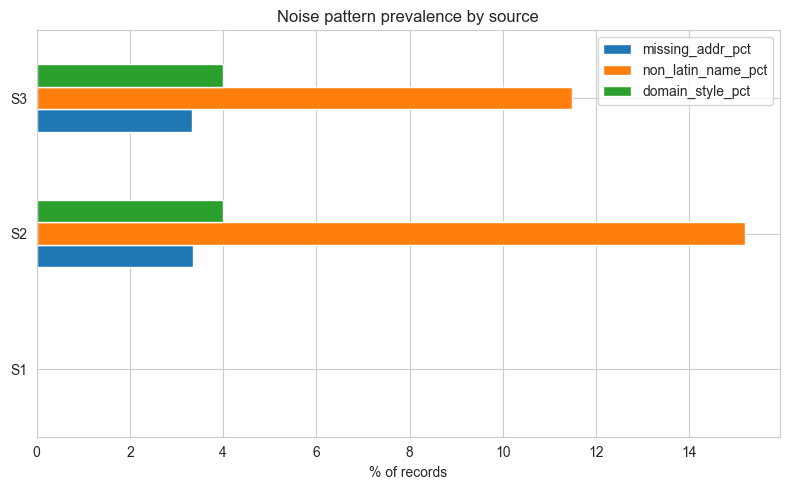

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
noise_summary[["missing_addr_pct", "non_latin_name_pct", "domain_style_pct"]].plot(kind="barh", ax=ax)
ax.set_xlabel("% of records")
ax.set_title("Noise pattern prevalence by source")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/01_noise_patterns_by_source.png", dpi=120)
plt.show()

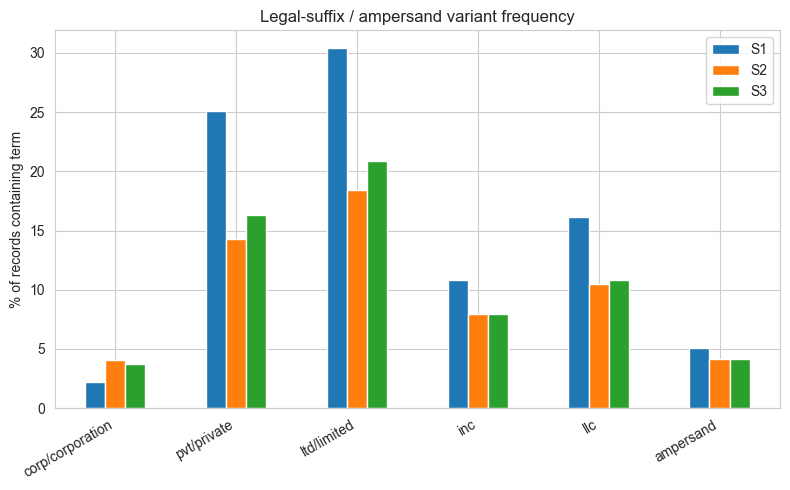

In [5]:
suffix_df = pd.DataFrame({
    "S1": noise_s1["suffix_hits_pct"],
    "S2": noise_s2["suffix_hits_pct"],
    "S3": noise_s3["suffix_hits_pct"],
})
fig, ax = plt.subplots(figsize=(8, 5))
suffix_df.plot(kind="bar", ax=ax)
ax.set_ylabel("% of records containing term")
ax.set_title("Legal-suffix / ampersand variant frequency")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/02_suffix_variant_frequency.png", dpi=120)
plt.show()

## 3. Ground-truth structure (Component 3)

Match-count distribution (KDE), singleton rate, country split, S2-vs-S3 fan-out — from
train ground truth only.

In [6]:
gt = gt.copy()
gt["match_count"] = gt["matched_entity_ids"].apply(lambda x: 0 if x == "" else len(x.split(",")))
gt = gt.merge(s1_train[["entity_id", "country"]], left_on="source1_entity_id", right_on="entity_id", how="left")
singleton_pct = 100 * (gt["match_count"] == 0).mean()
print(f"Singleton rate: {singleton_pct:.2f}%")
gt["match_count"].describe()

Singleton rate: 5.58%


count    1.765456e+06
mean     3.461233e+00
std      1.705333e+00
min      0.000000e+00
25%      2.000000e+00
50%      3.000000e+00
75%      5.000000e+00
max      1.100000e+01
Name: match_count, dtype: float64

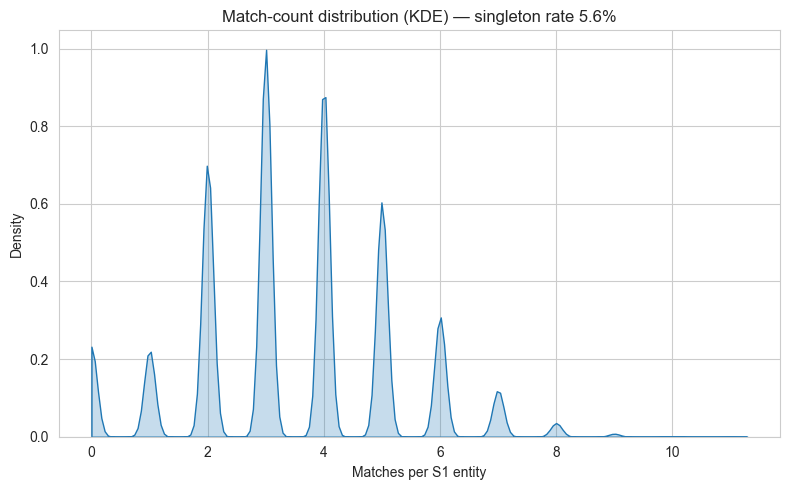

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=gt[gt.match_count <= 15], x="match_count", clip=(0, 15), fill=True, ax=ax)
ax.set_title(f"Match-count distribution (KDE) — singleton rate {singleton_pct:.1f}%")
ax.set_xlabel("Matches per S1 entity")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/03_match_count_kde.png", dpi=120)
plt.show()

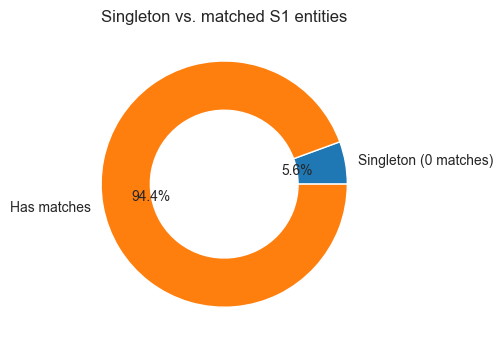

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
labels = ["Singleton (0 matches)", "Has matches"]
sizes = [(gt.match_count == 0).sum(), (gt.match_count > 0).sum()]
ax.pie(sizes, labels=labels, autopct="%1.1f%%", wedgeprops=dict(width=0.4))
ax.set_title("Singleton vs. matched S1 entities")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/04_singleton_donut.png", dpi=120)
plt.show()

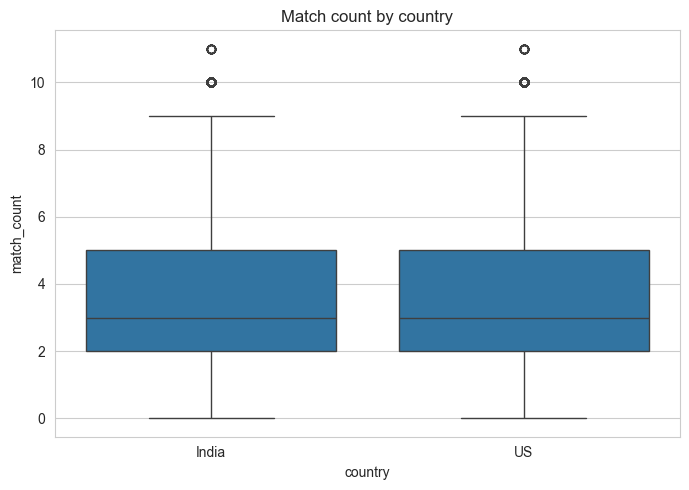

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=gt, x="country", y="match_count", ax=ax)
ax.set_title("Match count by country")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/05_match_count_by_country_box.png", dpi=120)
plt.show()

In [10]:
def fanout(ids):
    if ids == "":
        return pd.Series({"s2": 0, "s3": 0})
    parts = ids.split(",")
    return pd.Series({
        "s2": sum(1 for p in parts if p.startswith("S2-")),
        "s3": sum(1 for p in parts if p.startswith("S3-")),
    })
fanout_sample = gt.sample(min(100_000, len(gt)), random_state=42)["matched_entity_ids"].apply(fanout)
avg_s2, avg_s3 = fanout_sample["s2"].mean(), fanout_sample["s3"].mean()
print(f"Avg matches/entity — S2: {avg_s2:.3f}, S3: {avg_s3:.3f}")

Avg matches/entity — S2: 1.676, S3: 1.792


## 4. True-match vs. non-match similarity separation (Component 4) — key diagnostic

Samples true pairs from ground truth + non-match pairs (from the reservoir sample pool, each
verified not to be an actual match for that S1 entity), fetches the real records, computes
5 similarity features, and plots KDE + violin + box per feature.

In [11]:
log("Sampling true-match pairs...")
N_SAMPLE = 4000
gt_matched = gt[gt["match_count"] > 0]
sample_gt = gt_matched.sample(N_SAMPLE, random_state=42).copy()
sample_gt["picked_match"] = sample_gt["matched_entity_ids"].apply(lambda x: random.choice(x.split(",")))

s2_needed = set(sample_gt.loc[sample_gt.picked_match.str.startswith("S2-"), "picked_match"])
s3_needed = set(sample_gt.loc[sample_gt.picked_match.str.startswith("S3-"), "picked_match"])
log(f"Fetching {len(s2_needed)} S2 + {len(s3_needed)} S3 true-match records...")
s2_true_recs = U.fetch_records(f"{TRAIN_DIR}/train_source2.tsv", s2_needed)
s3_true_recs = U.fetch_records(f"{TRAIN_DIR}/train_source3.tsv", s3_needed)
log("True-match records fetched.")

s1_lookup = s1_train.set_index("entity_id")[["business_name", "business_address", "country"]].to_dict("index")

true_rows = []
for _, r in sample_gt.iterrows():
    s1id, m = r["source1_entity_id"], r["picked_match"]
    if s1id not in s1_lookup:
        continue
    rec = s2_true_recs.get(m) or s3_true_recs.get(m)
    if rec is None:
        continue
    true_rows.append({
        "s1_id": s1id, "match_id": m,
        "s1_name": s1_lookup[s1id]["business_name"], "s1_addr": s1_lookup[s1id]["business_address"],
        "m_name": rec["business_name"], "m_addr": rec["business_address"],
        "label": 1,
    })
log(f"Assembled {len(true_rows)} true-match rows.")

[ 129.9s] Sampling true-match pairs...
[ 130.2s] Fetching 1907 S2 + 2093 S3 true-match records...
[ 194.7s] True-match records fetched.
[ 313.2s] Assembled 4000 true-match rows.


In [12]:
log("Assembling non-match pairs from reservoir samples...")
pool = pd.concat([noise_s2["sample_df"], noise_s3["sample_df"]], ignore_index=True)

non_rows = []
s1_sample_for_nonmatch = s1_train.sample(N_SAMPLE, random_state=7).reset_index(drop=True)
pool_shuffled = pool.sample(frac=1.0, random_state=7).reset_index(drop=True)
pi = 0
gt_map = gt.set_index("source1_entity_id")["matched_entity_ids"].to_dict()
for _, r in s1_sample_for_nonmatch.iterrows():
    s1id = r["entity_id"]
    true_matches = set(gt_map.get(s1id, "").split(",")) if gt_map.get(s1id, "") else set()
    tries = 0
    while pi < len(pool_shuffled) and tries < 5:
        cand = pool_shuffled.iloc[pi]
        pi += 1
        tries += 1
        if cand["entity_id"] not in true_matches:
            non_rows.append({
                "s1_id": s1id, "match_id": cand["entity_id"],
                "s1_name": r["business_name"], "s1_addr": r["business_address"],
                "m_name": cand["business_name"], "m_addr": cand["business_address"],
                "label": 0,
            })
            break
log(f"Assembled {len(non_rows)} non-match rows.")

pairs = pd.DataFrame(true_rows + non_rows)
log(f"Total pairs for similarity analysis: {len(pairs)} (true={len(true_rows)}, non={len(non_rows)})")

[ 313.2s] Assembling non-match pairs from reservoir samples...
[ 319.3s] Assembled 4000 non-match rows.
[ 319.4s] Total pairs for similarity analysis: 8000 (true=4000, non=4000)


In [13]:
log("Computing similarity features...")
pairs["name_edit_sim"] = pairs.apply(lambda r: U.edit_sim(r.s1_name, r.m_name), axis=1)
pairs["name_token_jaccard"] = pairs.apply(lambda r: U.token_jaccard(r.s1_name, r.m_name), axis=1)
pairs["addr_edit_sim"] = pairs.apply(lambda r: U.edit_sim(r.s1_addr, r.m_addr), axis=1)
pairs["addr_token_jaccard"] = pairs.apply(lambda r: U.token_jaccard(r.s1_addr, r.m_addr), axis=1)
pairs["name_tfidf_cosine"] = U.pairwise_tfidf_cosine(pairs["s1_name"].tolist(), pairs["m_name"].tolist())
log("Similarity features computed.")
pairs.to_csv("../../../output/pairs_sample.csv", index=False)

FEATURES = ["name_edit_sim", "name_token_jaccard", "name_tfidf_cosine", "addr_edit_sim", "addr_token_jaccard"]
pairs[FEATURES + ["label"]].groupby("label").median()

[ 319.4s] Computing similarity features...
[ 323.3s] Similarity features computed.


,name_edit_sim,name_token_jaccard,name_tfidf_cosine,addr_edit_sim,addr_token_jaccard
label,,,,,
0,0.263158,0.0,0.012885,0.253521,0.0
1,0.813030,0.6,0.818374,0.517857,0.5


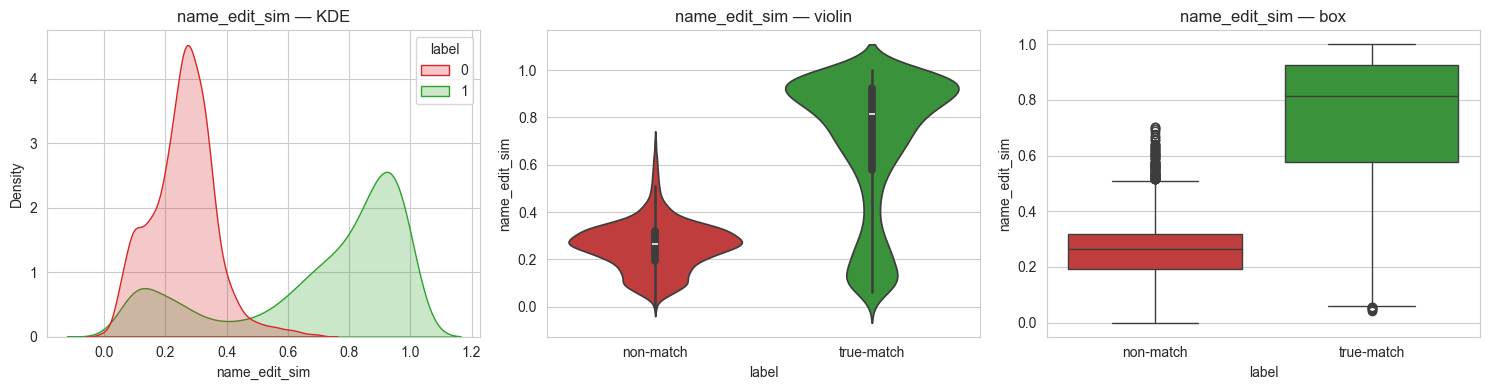

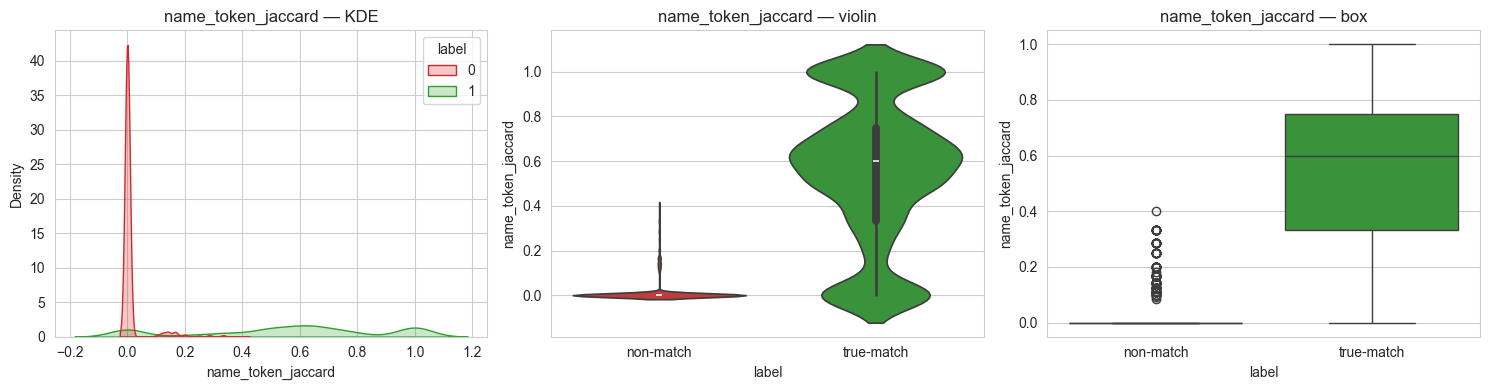

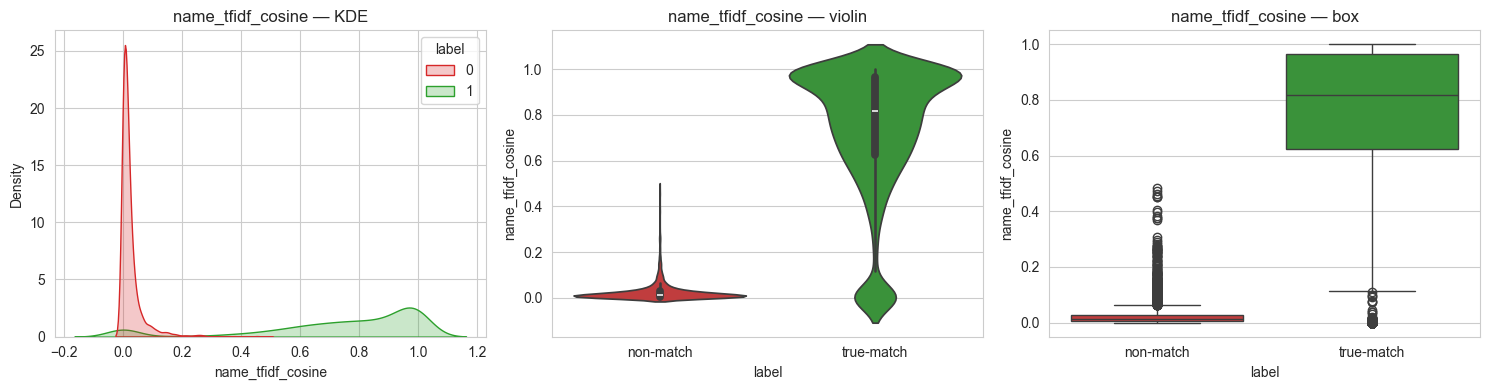

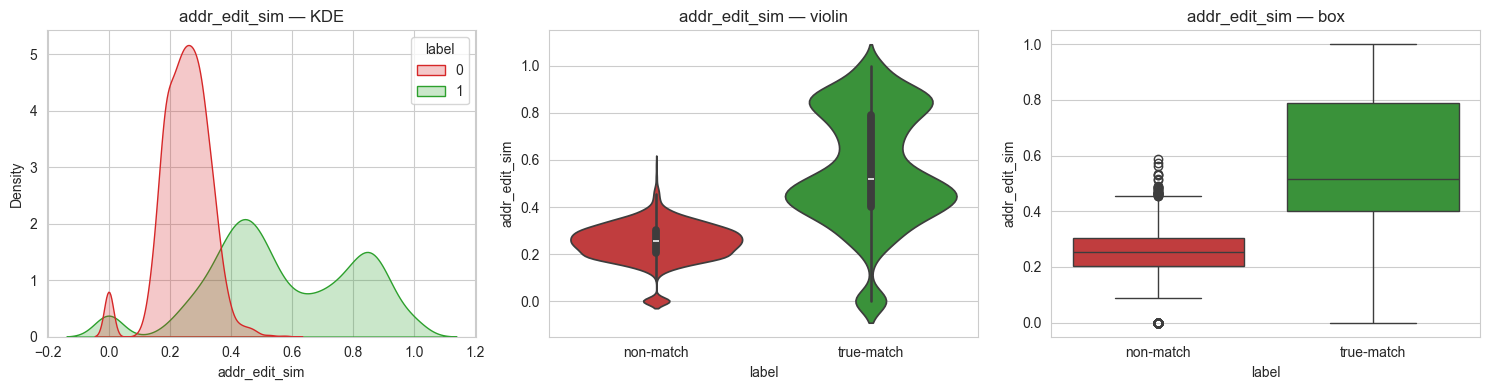

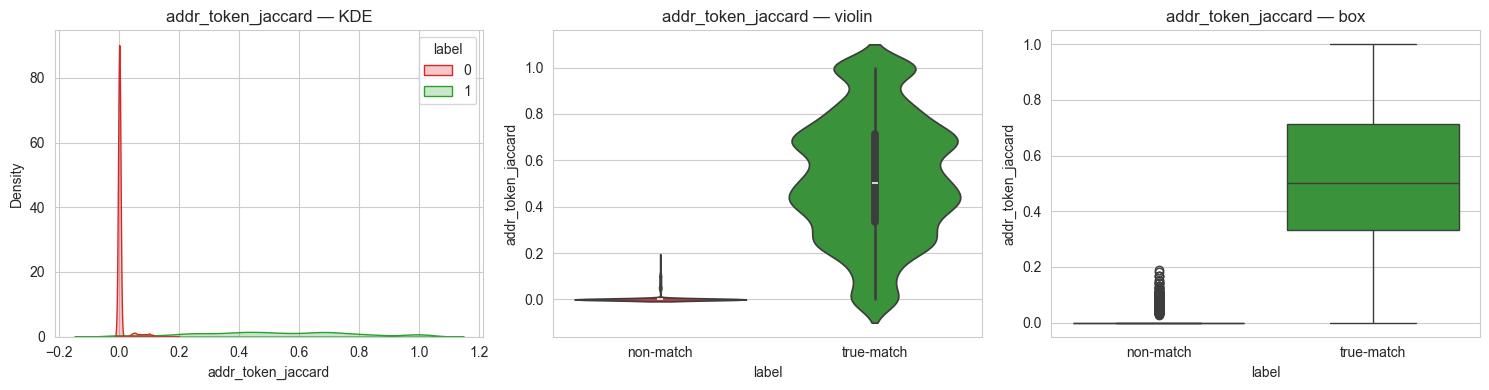

In [14]:
for feat in FEATURES:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.kdeplot(data=pairs, x=feat, hue="label", fill=True, common_norm=False, ax=axes[0],
                palette={0: "tab:red", 1: "tab:green"})
    axes[0].set_title(f"{feat} — KDE")
    sns.violinplot(data=pairs, x="label", y=feat, order=[0, 1], ax=axes[1],
                   palette=["tab:red", "tab:green"], hue="label", legend=False)
    axes[1].set_title(f"{feat} — violin")
    axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["non-match", "true-match"])
    sns.boxplot(data=pairs, x="label", y=feat, order=[0, 1], ax=axes[2],
                palette=["tab:red", "tab:green"], hue="label", legend=False)
    axes[2].set_title(f"{feat} — box")
    axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["non-match", "true-match"])
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/06_{feat}_separation.png", dpi=120)
    plt.show()

## 5. Feature ranking (Component 5)

Median gap (true-match − non-match) per feature, ranked — tells Phase 3 which features to weight.

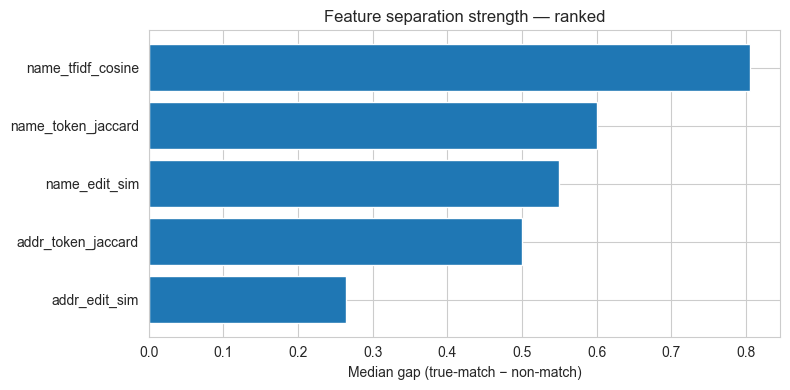

,feature,true_match_median,non_match_median,gap
2,name_tfidf_cosine,0.818374,0.012885,0.805490
1,name_token_jaccard,0.600000,0.000000,0.600000
0,name_edit_sim,0.813030,0.263158,0.549872
4,addr_token_jaccard,0.500000,0.000000,0.500000
3,addr_edit_sim,0.517857,0.253521,0.264336


In [15]:
gap_rows = []
for feat in FEATURES:
    tm = pairs.loc[pairs.label == 1, feat].median()
    nm = pairs.loc[pairs.label == 0, feat].median()
    gap_rows.append({"feature": feat, "true_match_median": tm, "non_match_median": nm, "gap": tm - nm})
gap_df = pd.DataFrame(gap_rows).sort_values("gap", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(gap_df["feature"], gap_df["gap"], color="tab:blue")
ax.set_xlabel("Median gap (true-match − non-match)")
ax.set_title("Feature separation strength — ranked")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/07_feature_gap_ranking.png", dpi=120)
plt.show()
gap_df.sort_values("gap", ascending=False)

## 6. Precision-at-threshold (Component 6)

For the top-ranked feature, precision/recall on the balanced sample at each threshold —
this is the number Phase 2/3 actually need to set a working decision threshold
(F_0.5 is precision-heavy, so this matters more than the raw separation gap).

In [16]:
top_feat = gap_df.sort_values("gap", ascending=False).iloc[0]["feature"]
thresholds = np.arange(0.1, 0.96, 0.05)
prec_rows = []
for t in thresholds:
    pred_pos = pairs[pairs[top_feat] >= t]
    prec = (pred_pos["label"] == 1).mean() if len(pred_pos) else np.nan
    recall = ((pairs["label"] == 1) & (pairs[top_feat] >= t)).sum() / (pairs["label"] == 1).sum()
    prec_rows.append({"threshold": round(t, 2), "precision_on_balanced_sample": prec, "recall_on_sample": recall})
prec_df = pd.DataFrame(prec_rows)
print(f"Top feature: {top_feat}")
prec_df

Top feature: name_tfidf_cosine


,threshold,precision_on_balanced_sample,recall_on_sample
0,0.10,0.949663,0.91500
1,0.15,0.974113,0.91250
2,0.20,0.985931,0.91100
3,0.25,0.990984,0.90675
4,0.30,0.996417,0.90375
5,0.35,0.996663,0.89600
6,0.40,0.998023,0.88350
7,0.45,0.998279,0.87000
8,0.50,1.000000,0.84500
9,0.55,1.000000,0.81550


## 7. Blocking-key feasibility (Component 7)

**Recall here = pair completeness** (fraction of true-match pairs sharing a candidate
blocking key), checked directly against the sampled true pairs — not model recall, since no
matcher exists yet. This is the metric that matters for blocking: precision/F1/ROC-AUC don't
apply at this stage (see discussion — blocking only includes/excludes candidates, it doesn't
rank them).

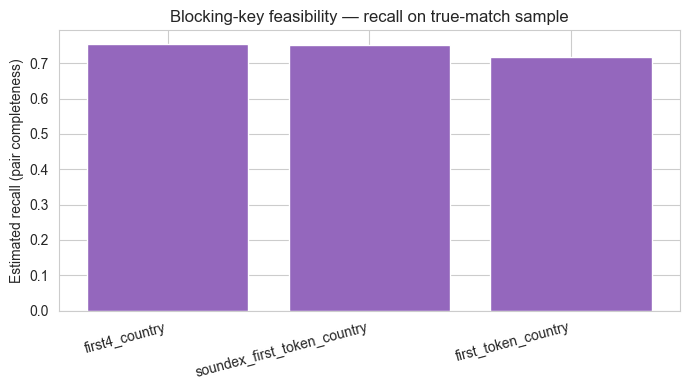

,blocking_key,recall_estimate
0,first4_country,0.75550
2,soundex_first_token_country,0.75300
1,first_token_country,0.71925


In [17]:
blocking_results = []
for key_name, key_fn in U.BLOCKING_KEYS.items():
    hits, checked = 0, 0
    for _, r in pairs[pairs.label == 1].iterrows():
        k1, k2 = key_fn(r.s1_name, ""), key_fn(r.m_name, "")
        checked += 1
        if k1 == k2:
            hits += 1
    blocking_results.append({"blocking_key": key_name, "recall_estimate": hits / checked if checked else 0})
blocking_df = pd.DataFrame(blocking_results).sort_values("recall_estimate", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(blocking_df["blocking_key"], blocking_df["recall_estimate"], color="tab:purple")
ax.set_ylabel("Estimated recall (pair completeness)")
ax.set_title("Blocking-key feasibility — recall on true-match sample")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/08_blocking_recall_estimate.png", dpi=120)
plt.show()
blocking_df

## 8. Normalization rule validation (Component 8)

Each draft rule is applied to the **real sampled records** and the true/non-match gap is
re-measured — a rule is only accepted if it *actually* widens the gap on this data, not
because it sounds reasonable.

In [18]:
rule_results = []
base_gap = gap_df.set_index("feature").loc["name_edit_sim", "gap"]
for rule_name, rule_fn in U.DRAFT_RULES.items():
    s1n = pairs["s1_name"].apply(rule_fn)
    mn = pairs["m_name"].apply(rule_fn)
    sims = [U.edit_sim(a, b) for a, b in zip(s1n, mn)]
    tmp = pairs.copy()
    tmp["sim_after"] = sims
    tm = tmp.loc[tmp.label == 1, "sim_after"].median()
    nm = tmp.loc[tmp.label == 0, "sim_after"].median()
    new_gap = tm - nm
    rule_results.append({"rule": rule_name, "baseline_gap": base_gap, "gap_after_rule": new_gap,
                          "delta": new_gap - base_gap, "accepted": bool(new_gap >= base_gap)})
rule_df = pd.DataFrame(rule_results)
rule_df

,rule,baseline_gap,gap_after_rule,delta,accepted
0,lowercase,0.549872,0.558974,0.009103,True
1,punct_strip,0.549872,0.546056,-0.003816,False
2,ampersand_to_and,0.549872,0.549408,-0.000463,False
3,whitespace_collapse,0.549872,0.551160,0.001289,True
4,suffix_canonicalize,0.549872,0.565939,0.016067,True
5,domain_strip,0.549872,0.555024,0.005152,True


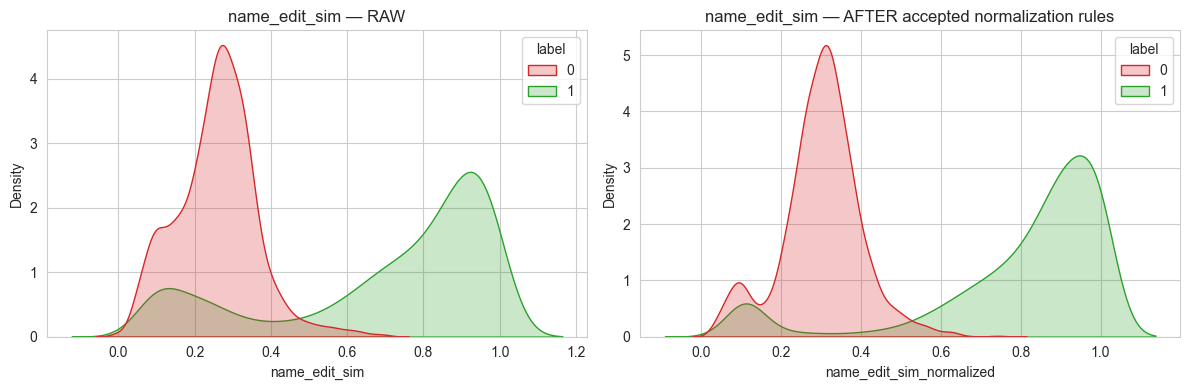

In [19]:
accepted_rules = {k: v for k, v in U.DRAFT_RULES.items()
                   if rule_df.set_index("rule").loc[k, "accepted"]}
s1n_all = pairs["s1_name"].apply(lambda s: U.apply_all_rules(s, accepted_rules))
mn_all = pairs["m_name"].apply(lambda s: U.apply_all_rules(s, accepted_rules))
pairs["name_edit_sim_normalized"] = [U.edit_sim(a, b) for a, b in zip(s1n_all, mn_all)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=pairs, x="name_edit_sim", hue="label", fill=True, common_norm=False, ax=axes[0],
            palette={0: "tab:red", 1: "tab:green"})
axes[0].set_title("name_edit_sim — RAW")
sns.kdeplot(data=pairs, x="name_edit_sim_normalized", hue="label", fill=True, common_norm=False, ax=axes[1],
            palette={0: "tab:red", 1: "tab:green"})
axes[1].set_title("name_edit_sim — AFTER accepted normalization rules")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/09_normalization_before_after.png", dpi=120)
plt.show()

## 9. Export validated normalization rules (Component 9)

Only the *accepted* rules are exported — this file becomes Phase 2's direct input.

In [20]:
import inspect
accepted_names = list(accepted_rules.keys())
with open("normalization_rules.py", "w") as f:
    f.write('"""Validated normalization rules from Phase 1 EDA — accepted set only.\n')
    f.write(f'Accepted: {accepted_names}\n"""\n')
    f.write("import re\n\n")
    f.write("DOMAIN_RE = re.compile(r'\\.(?:com|net|org|co|in|biz|io)\\b', re.IGNORECASE)\n\n")
    for name in accepted_names:
        f.write(inspect.getsource(U.DRAFT_RULES[name]) + "\n")
    f.write("def normalize(s):\n")
    for name in accepted_names:
        f.write(f"    s = {U.DRAFT_RULES[name].__name__}(s)\n")
    f.write("    return s\n")
print(f"Exported normalization_rules.py — accepted rules: {accepted_names}")

Exported normalization_rules.py — accepted rules: ['lowercase', 'whitespace_collapse', 'suffix_canonicalize', 'domain_strip']


## 10. Findings write-up (Component 10)

Consolidated report → `output/eda_findings.md`, the direct handoff document for Phase 2.

In [22]:
%pip install tabulate
findings_path = "../../../output/eda_findings.md"
with open(findings_path, "w") as f:
    f.write("# Phase 1 — EDA Findings\n\n")
    f.write("## 1. Noise profile by source\n\n")
    f.write(noise_summary.to_markdown() + "\n\n")
    f.write("## 2. Ground-truth structure\n\n")
    f.write(f"- Singleton rate: **{singleton_pct:.2f}%**\n")
    f.write(f"- Avg matches/entity — S2: {avg_s2:.3f}, S3: {avg_s3:.3f}\n\n")
    f.write("## 3. Feature separation ranking\n\n")
    f.write(gap_df.sort_values('gap', ascending=False).to_markdown(index=False) + "\n\n")
    f.write(f"## 4. Precision-at-threshold (top feature: `{top_feat}`, balanced sample)\n\n")
    f.write(prec_df.to_markdown(index=False) + "\n\n")
    f.write("## 5. Blocking-key feasibility (recall estimate on true-match sample)\n\n")
    f.write(blocking_df.to_markdown(index=False) + "\n\n")
    f.write("## 6. Normalization rule validation\n\n")
    f.write(rule_df.to_markdown(index=False) + "\n\n")
    f.write(f"Accepted rules exported to `normalization_rules.py`: {accepted_names}\n\n")
    f.write("## 7. Phase 2 handoff checklist\n\n")
    f.write("- [ ] Use accepted normalization rules before computing any blocking key\n")
    f.write(f"- [ ] Best blocking key by recall estimate: **{blocking_df.iloc[0]['blocking_key']}**\n")
    f.write("- [ ] Consider country-specific blocking fallback (India landmark-based addresses)\n")
    f.write(f"- [ ] Top discriminative feature for matching model: **{top_feat}**\n")
    f.write(f"- [ ] Singleton rate ({singleton_pct:.1f}%) — ensure model can predict empty match lists confidently\n")
print(f"Wrote {findings_path}")
log("PHASE 1 EDA COMPLETE.")

Note: you may need to restart the kernel to use updated packages.
Wrote ../../../output/eda_findings.md
[ 429.2s] PHASE 1 EDA COMPLETE.


## Next step

Phase 1 is complete. Outputs handed to Phase 2 (blocking / candidate generation):
`normalization_rules.py`, the feature ranking, the precision-at-threshold table, and the
blocking-key recall estimates in `eda_findings.md`.

**Do not re-run this notebook with different sample sizes/seeds mid-hackathon** — keep the
findings comparable across the team, same as the Phase 0 split.